# Agentic AI for Autonomous Investment Research

## Planner and Agent Orchestration (Engineer 1)

This section demonstrates **Planning**, **Routing** and **Dynamic Tool Use**:

1. The Planner turns a symbol and question into a validated, ordered research plan (Groq `openai/gpt-oss-120b`, available within Free Plan limits, with a deterministic rule-based fallback).
2. Routing happens inside the Planner: every subagent is either selected or skipped, each with a reason and confidence.
3. The Orchestrator runs only the selected subagents, exposes only the planned tools to each one, and logs every tool call.
4. Partial failures become warnings and limitations instead of stopping the run.
5. Aggregated evidence is handed to the Report Generator (Engineer 3).

> Educational research only; not personalized investment advice.

Set `GROQ_API_KEY` in a local `.env` file (see `.env.example`) before running to use Groq for planning.

In [11]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.bootstrap import build_runtime
from src.orchestration_viz import (
    plan_table, routing_table, tool_log_table, execution_table,
    plot_plan, plot_routing_matrix, plot_execution_timeline, plot_tool_calls,
)

pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 160)

rt = build_runtime()
print('LLM key loaded:', rt.llm.available, '| model:', rt.llm.model)
print('Planner mode  :', 'Groq (LLM)' if rt.llm.available else 'rule-based fallback (set GROQ_API_KEY in .env)')
print('\nIntegration status of other engineers\' components (stub = placeholder until merged):')
display(pd.Series(rt.integration, name='status').to_frame())

LLM key loaded: True | model: openai/gpt-oss-120b
Planner mode  : Groq (LLM)

Integration status of other engineers' components (stub = placeholder until merged):


,status
memory,missing
market_agent,stub
earnings_agent,stub
news_agent,stub
data_tools,stub
report_pipeline,missing


## 1. Planning

A broad request produces a plan that covers every specialist.

Planner mode: llm | scope: comprehensive
Intent      : Provide comprehensive investment research for MSFT
Rationale   : The question requests a full investment analysis, so all three specialized subagents are required to cover market performance, financial fundamentals, and recent news.


,step,subagent,description,depends_on,tools,completion_criteria,status
0,S1,market_agent,"Gather price and benchmark history, compute performance metrics, and retrieve macro se...",-,"get_price_history, get_benchmark_history, get_macro_series","Price history and benchmark data retrieved, performance metrics calculated, and macro ...",pending
1,S2,earnings_agent,"Retrieve financial statements and analyze income statement, balance sheet, cash flow, ...",-,"get_financial_statements, get_sec_filings",Financial statements downloaded and key financial ratios and risk metrics computed.,pending
2,S3,news_agent,"Collect recent company news, identify catalysts and risks, and produce a source‑backed...",-,get_company_news,Recent news items gathered and summarized with identified catalysts and risks.,pending


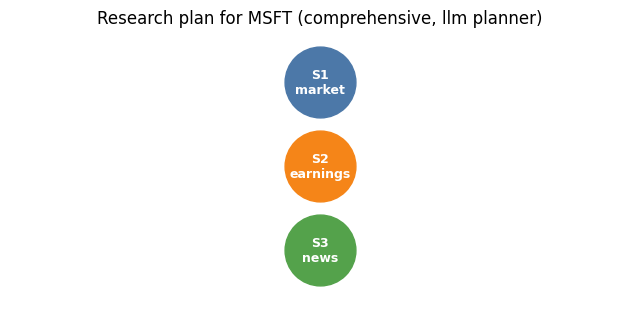

In [12]:
state = rt.orchestrator.plan('MSFT', 'Produce comprehensive investment research')
print('Planner mode:', state.plan.planner_mode, '| scope:', state.plan.scope)
print('Intent      :', state.plan.intent)
print('Rationale   :', state.plan.rationale)
display(plan_table(state.plan))
plot_plan(state.plan)
plt.show()
for w in state.warnings:
    print('WARNING:', w.source, '-', w.message)

Each step has a concrete completion criterion and the exact tools the subagent may call. The plan is validated (known subagents, allowed tools, unique ids, no dependency cycles) before anything runs.

## 2. Routing: narrow questions select narrow sets

Five questions, including a multi-subagent route with a dependency (earnings must precede the price-reaction analysis) and a macro question that adds an optional tool.

Analyze one-year price performance
   S1 market_agent: tools=['get_price_history', 'get_benchmark_history']
Analyze revenue and margin trends
   S1 earnings_agent: tools=['get_financial_statements']
Summarize recent product announcements
   S1 news_agent: tools=['get_company_news']
Analyze earnings and the resulting share-price movement
   S1 earnings_agent: tools=['get_financial_statements']
   S2 market_agent (after S1): tools=['get_price_history', 'get_benchmark_history']
Analyze price performance given interest rates and inflation
   S1 market_agent: tools=['get_price_history', 'get_benchmark_history', 'get_macro_series']
Produce comprehensive investment research
   S1 market_agent: tools=['get_price_history', 'get_benchmark_history']
   S2 earnings_agent: tools=['get_financial_statements']
   S3 news_agent: tools=['get_company_news']


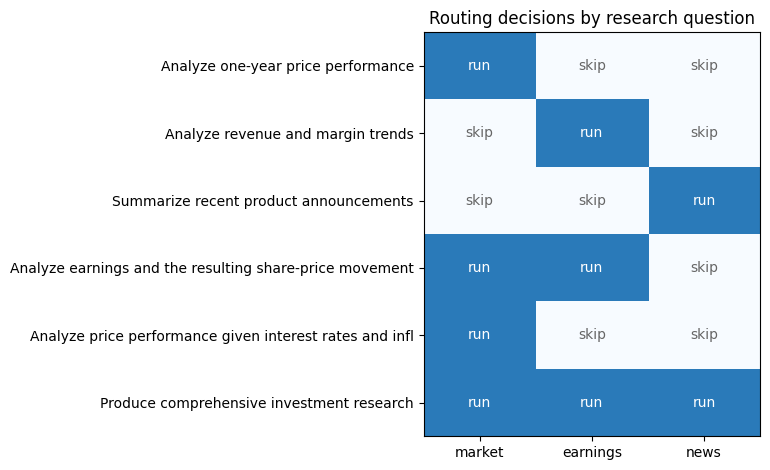

In [3]:
QUESTIONS = [
    'Analyze one-year price performance',
    'Analyze revenue and margin trends',
    'Summarize recent product announcements',
    'Analyze earnings and the resulting share-price movement',
    'Analyze price performance given interest rates and inflation',
    'Produce comprehensive investment research',
]

cases = {}
for q in QUESTIONS:
    s = rt.orchestrator.plan('AAPL', q)
    cases[q] = s.routing_log
    print(f'{q}')
    for step in s.plan.steps:
        dep = f' (after {", ".join(step.depends_on)})' if step.depends_on else ''
        print(f'   {step.step_id} {step.subagent}{dep}: tools={step.tools}')

plot_routing_matrix(cases, rt.subagents.names())
plt.show()

In [4]:
# Selected AND skipped subagents, each with a reason and confidence.
display(routing_table(cases[QUESTIONS[3]]))
display(routing_table(cases[QUESTIONS[0]]))

,decision,subagent,task,reason,confidence,status
0,SELECTED,earnings_agent,"Analyze AAPL revenue, profit, margin and cash-flow trends from financial statements",Question mentions: earnings.,0.7,pending
1,SELECTED,market_agent,"Analyze AAPL price performance against the benchmark: returns, rolling volatility and ...","Question mentions: movement, price, share-price.",0.9,pending
2,skipped,news_agent,none,"The question does not ask about recent news, events or announcements.",0.8,pending


,decision,subagent,task,reason,confidence,status
0,SELECTED,market_agent,"Analyze AAPL price performance against the benchmark: returns, rolling volatility and ...",Question mentions: price.,0.7,pending
1,skipped,earnings_agent,none,"The question does not ask about revenue, profit, margins, cash flow or financial state...",0.8,pending
2,skipped,news_agent,none,"The question does not ask about recent news, events or announcements.",0.8,pending


The matrix shows routing is conditional: the number of selected subagents changes with the question, so this is not a fixed pipeline. The optional macro tool appears only for the macro question.

## 3. Lessons from earlier runs shape the plan

The Planner receives lessons from Memory (Engineer 3) as guidance, never as evidence. The lesson below is a hand-written stand-in to show the mechanism; real lessons come from run reflection.

In [5]:
lesson = [{
    'memory_id': 'DEMO-1',
    'lesson': 'Price-only answers lacked event context; include recent news.',
    'score': 0.9,
    'hint': {'require_subagents': ['news_agent'], 'extra_criteria': 'state data limitations explicitly'},
}]
q = 'Analyze one-year price performance'
before = rt.planner.create_plan('AAPL', q)
after = rt.planner.create_plan('AAPL', q, lesson)
print('Without lesson:', before.plan.selected_subagents)
print('With lesson   :', after.plan.selected_subagents, '| lessons applied:', after.plan.lessons_applied)
display(routing_table(after.routing))

Without lesson: ['market_agent']
With lesson   : ['market_agent', 'news_agent'] | lessons applied: ['DEMO-1']


,decision,subagent,task,reason,confidence,status
0,SELECTED,market_agent,"Analyze AAPL price performance against the benchmark: returns, rolling volatility and ...",Question mentions: price.,0.7,pending
1,SELECTED,news_agent,"Summarize recent AAPL news through the five-stage prompt chain: events, catalysts and ...",Added by lesson DEMO-1: Price-only answers lacked event context; include recent news.,0.7,pending
2,skipped,earnings_agent,none,"The question does not ask about revenue, profit, margins, cash flow or financial state...",0.8,pending


## 4. Orchestration and Dynamic Tool Use

The Orchestrator runs steps in dependency order. Each subagent gets a tool session limited to the tools in its plan step; every call is logged with status, duration and a result summary.

,step_id,subagent,status,started_at,duration_ms,tools_allowed,tool_calls,message
0,S1,earnings_agent,success,2026-10-11T09:16:17+00:00,0.08,[get_financial_statements],1,[STUB] earnings_agent executed 1/1 planned tool calls; no analysis performed.
1,S2,market_agent,success,2026-10-11T09:16:17+00:00,0.09,"[get_price_history, get_benchmark_history]",2,[STUB] market_agent executed 2/2 planned tool calls; no analysis performed.


,caller,tool_name,status,duration_ms,output_summary,error,retrieved_at
0,orchestrator,get_company_profile,success,0.0,dict with 3 keys,None,2026-10-11T09:16:17+00:00
1,earnings_agent,get_financial_statements,success,0.0,dict with 3 keys,None,2026-10-11T09:16:17+00:00
2,market_agent,get_price_history,success,0.0,dict with 3 keys,None,2026-10-11T09:16:17+00:00
3,market_agent,get_benchmark_history,success,0.0,dict with 3 keys,None,2026-10-11T09:16:17+00:00


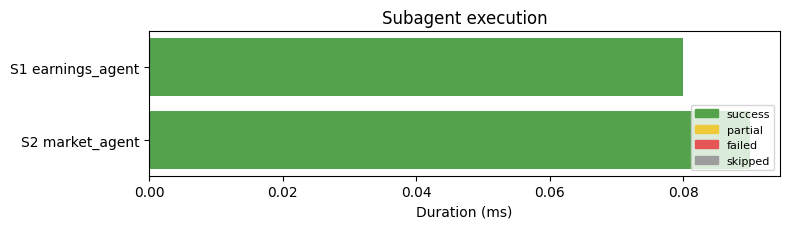

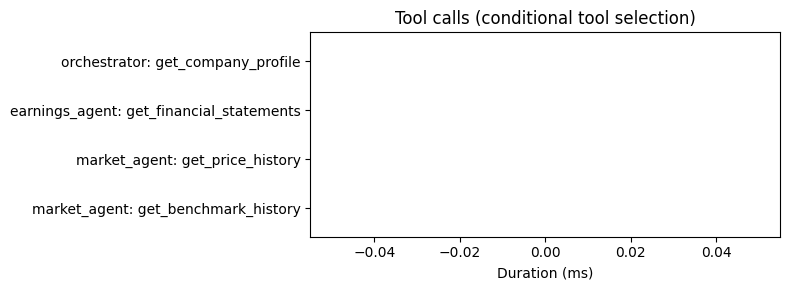

Subagents that ran: ['earnings_agent', 'market_agent']
News tool called?   False


In [13]:
state = rt.orchestrator.run('MSFT', 'Analyze earnings and the resulting share-price movement')
display(execution_table(state))
display(tool_log_table(state))
plot_execution_timeline(state)
plt.show()
plot_tool_calls(state)
plt.show()
print('Subagents that ran:', state.selected_subagents)
print('News tool called?  ', any(c['tool_name'] == 'get_company_news' for c in state.tool_call_log))

Only the earnings and market tools were called; the news tool never ran because the plan did not select it.

## 5. Partial failure does not stop the workflow

The News subagent is replaced with one that raises an error. The other subagents still complete; the failure becomes a warning and a limitation for the report.

In [7]:
original_news_agent = rt.subagents.get('news_agent').fn

def failing_news_agent(state, tools, step):
    raise RuntimeError('simulated news API outage')

rt.subagents.attach('news_agent', failing_news_agent)
try:
    failed_run = rt.orchestrator.run('AAPL', 'Produce comprehensive investment research')
finally:
    rt.subagents.attach('news_agent', original_news_agent)

display(execution_table(failed_run)[['step_id', 'subagent', 'status', 'tool_calls', 'message']])
print('Coverage   :', failed_run.aggregated['coverage'])
print('Limitations:')
for item in failed_run.aggregated['limitations']:
    print('  -', item['agent'], ':', item['text'])
print('Errors     :', [w.message for w in failed_run.warnings if w.severity == 'error'])

,step_id,subagent,status,tool_calls,message
0,S1,market_agent,success,2,[STUB] market_agent executed 2/2 planned tool calls; no analysis performed.
1,S2,earnings_agent,success,1,[STUB] earnings_agent executed 1/1 planned tool calls; no analysis performed.
2,S3,news_agent,failed,0,RuntimeError: simulated news API outage


Coverage   : {'market_agent': 'success', 'earnings_agent': 'success', 'news_agent': 'failed'}
Limitations:
  - market_agent : Stub implementation: no real data was analysed.
  - earnings_agent : Stub implementation: no real data was analysed.
  - news_agent : news_agent did not complete (failed); no analysis available.
Errors     : ['Subagent failed: RuntimeError: simulated news API outage']


## 6. Hand-off to the Report Generator

`state.aggregated` is the single structure Engineer 3 consumes: per-agent status, findings, risks, limitations, de-duplicated evidence with ids, coverage, warnings and memories used. When `src/report_generator.py` exposes `run_report_pipeline(state)`, `build_runtime()` wires it in automatically.

In [8]:
agg = state.aggregated
print({k: (len(v) if isinstance(v, (list, dict)) else v) for k, v in agg.items() if k not in ('question',)})
print('Report pipeline:', rt.integration['report_pipeline'])

{'symbol': 'AAPL', 'company_profile': 3, 'agents': 2, 'coverage': 2, 'findings': 0, 'risks': 0, 'limitations': 2, 'evidence': 0, 'warnings': 1, 'memories_used': 0, 'aggregated_at': '2026-10-11T09:07:15+00:00'}
Report pipeline: missing
